# 02 — Model Experiments
## Multiclass Classification of Hardware Failures in Microwave Telecommunication Networks

**Owner:** Avishi Poddar (model training) · **Data:** `dataset_TNSM_06995_v2.csv` (Di Cicco et al., IEEE TNSM 2024)

**Task.** Each row is one 15-minute observation window from a microwave link in which a hardware failure was recorded.
The 164 features `alarm_0 … alarm_163` are the number of seconds (0–900) each anonymised alarm was active.
Predict the recorded failure category: **0 = IDU, 1 = ODU, 2 = Cable, 3 = Power**. This is failure-cause *identification*, not forecasting.

**Protocol (fixed before looking at any test score)**
1. Group rows by identical 164-alarm vector → leakage-safe splits (`StratifiedGroupKFold`).
2. Hold out one grouped fold (~20 %) as the untouched test set.
3. Tune every model × feature representation with grouped 5-fold CV on the training part; **select by CV macro-F1**.
4. Score the selected pipeline once on the test set; full metrics + confusion matrix.
5. Extras: plain vs grouped split (leakage check), class weighting / SMOTE, which alarms are most informative.

In [1]:
import sys, time, warnings, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import joblib

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from features import load_data, vector_groups, to_binary, to_bins, CLASS_NAMES, TARGET

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix)
try:
    from xgboost import XGBClassifier          # needs libomp on macOS: brew install libomp
    HAS_XGB = True
except Exception as e:
    XGBClassifier, HAS_XGB = None, False
    print('XGBoost unavailable, skipping it:', type(e).__name__)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import sklearn, imblearn
XGB_VERSION = __import__('xgboost').__version__ if HAS_XGB else 'not installed'

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 42
DATA = ROOT / "data" / "dataset_TNSM_06995_v2.csv"
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
REP = ROOT / "reports"; MOD = ROOT / "models"; MOD.mkdir(exist_ok=True)
print("python", sys.version.split()[0], "| sklearn", sklearn.__version__, "| xgboost", XGB_VERSION,
      "| imblearn", imblearn.__version__, "| pandas", pd.__version__)

# chart styling (light surface, recessive chrome)
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # blue, orange, aqua, yellow (fixed order)
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "figure.dpi": 110,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2,
    "text.color": INK, "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False, "axes.axisbelow": True,
    "legend.frameon": False,
})

XGBoost unavailable, skipping it: XGBoostError


python 3.14.3 | sklearn 1.9.1 | xgboost not installed | imblearn 0.14.2 | pandas 3.0.6


## 1. Load and validate

In [2]:
df, X, y = load_data(DATA)
print("shape", df.shape, "| missing", int(df.isna().sum().sum()),
      "| out of [0,900]", int(((X < 0) | (X > 900)).sum().sum()),
      "| constant features", int((X.nunique() <= 1).sum()))
assert set(y.unique()) == {0, 1, 2, 3}
pd.DataFrame({"count": y.value_counts().sort_index(),
              "share": y.value_counts(normalize=True).sort_index().round(4)}).rename(index=CLASS_NAMES)

shape (1669, 165) | missing 0 | out of [0,900] 0 | constant features 45


,count,share
label,,
IDU,515,0.3086
ODU,611,0.3661
Cable,207,0.1240
Power,336,0.2013


## 2. Duplicate input vectors and label conflicts
`df.duplicated()` in the EDA included the label. Here we group on the **164 alarm columns only**.

In [3]:
groups = vector_groups(X)
gs = pd.Series(groups)
size = gs.map(gs.value_counts())
labels_per_vec = pd.Series(y.values).groupby(groups).nunique()
dup_summary = {
    "rows": len(X),
    "unique_input_vectors": int(gs.nunique()),
    "rows_whose_vector_repeats": int((size > 1).sum()),
    "largest_group_size": int(size.max()),
    "vectors_with_conflicting_labels": int((labels_per_vec > 1).sum()),
}
print(json.dumps(dup_summary, indent=2))
print("\nUnique vectors per class:")
print(pd.Series(y.values).groupby(y.values).apply(lambda s: gs[s.index].nunique()).rename(index=CLASS_NAMES))

{
  "rows": 1669,
  "unique_input_vectors": 1135,
  "rows_whose_vector_repeats": 584,
  "largest_group_size": 69,
  "vectors_with_conflicting_labels": 0
}

Unique vectors per class:
IDU      473
ODU      273
Cable    122
Power    267
dtype: int64


**Reading.** No identical vector carries two different labels, so the duplicates are not label noise — but the same pattern can repeat dozens of times.
A random row split would put copies of a pattern in both train and test and inflate scores, so every split below is **grouped by vector**.
Duplicates are kept (they are plausible repeated observations), not deleted.

## 3. Held-out test split (grouped, stratified)

In [4]:
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(X, y, groups))
X_tr, X_te, y_tr, y_te = X.iloc[train_idx], X.iloc[test_idx], y.iloc[train_idx], y.iloc[test_idx]
g_tr, g_te = groups[train_idx], groups[test_idx]
assert not set(g_tr) & set(g_te), "a vector appears in both train and test"
split_tbl = pd.DataFrame({"train": y_tr.value_counts().sort_index(), "test": y_te.value_counts().sort_index()}).rename(index=CLASS_NAMES)
split_tbl.loc["total"] = split_tbl.sum()
print(f"train rows {len(train_idx)}, test rows {len(test_idx)} ({len(test_idx)/len(X):.1%}); no shared vectors")
split_tbl

train rows 1335, test rows 334 (20.0%); no shared vectors


,train,test
label,,
IDU,412,103
ODU,489,122
Cable,165,42
Power,269,67
total,1335,334


## 4. Feature representations and model pipelines
| Rep | Definition | Used by linear/SVM/KNN/NB | Used by trees |
|---|---|---|---|
| **raw** | seconds active, 0–900 | standardised | as is |
| **binary** | 1 if alarm active at all (paper Mode-1) | as is | as is |
| **binned** | 0 off · 1 = 1–45 s · 2 = 46–450 s · 3 = 451–900 s (paper Mode-2) | **one-hot encoded** | ordinal codes |

Every step (constant-feature removal, scaling, encoding) is inside the pipeline, so it is re-fit on each training fold only.

In [5]:
SCALE_SENSITIVE = {"LogReg-L2", "LogReg-L2-balanced", "LogReg-L1", "SVM-linear", "SVM-RBF", "KNN", "NaiveBayes"}

def prep_steps(rep, model_name):
    steps = []
    if rep == "binary": steps.append(("rep", FunctionTransformer(to_binary)))
    if rep == "binned": steps.append(("rep", FunctionTransformer(to_bins)))
    steps.append(("drop_const", VarianceThreshold(0.0)))
    if model_name in SCALE_SENSITIVE:
        if rep == "raw" and model_name != "NaiveBayes": steps.append(("scale", StandardScaler()))
        if rep == "binned": steps.append(("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)))
    return steps

C_GRID = [0.01, 0.1, 1, 10]
def model_and_grid(name, rep):
    if name == "Dummy":              return DummyClassifier(strategy="most_frequent"), {}
    if name == "LogReg-L2":          return LogisticRegression(l1_ratio=0, max_iter=5000), {"clf__C": C_GRID}
    if name == "LogReg-L2-balanced": return LogisticRegression(l1_ratio=0, max_iter=5000, class_weight="balanced"), {"clf__C": C_GRID}
    if name == "LogReg-L1":          return LogisticRegression(l1_ratio=1, solver="saga", max_iter=5000, tol=1e-3, random_state=SEED), {"clf__C": C_GRID}
    if name == "SVM-linear":         return SVC(kernel="linear"), {"clf__C": C_GRID}
    if name == "SVM-RBF":            return SVC(kernel="rbf"), {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 0.01]}
    if name == "DecisionTree":       return DecisionTreeClassifier(random_state=SEED), {"clf__max_depth": [5, 10, None], "clf__min_samples_leaf": [1, 5]}
    if name == "RandomForest":       return RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1), {"clf__max_features": ["sqrt", 0.3], "clf__min_samples_leaf": [1, 3]}
    if name == "XGBoost":            return XGBClassifier(n_estimators=300, random_state=SEED, n_jobs=2, tree_method="hist", eval_metric="mlogloss"), {"clf__max_depth": [3, 6], "clf__learning_rate": [0.05, 0.1]}
    if name == "KNN":                return KNeighborsClassifier(), {"clf__n_neighbors": [3, 7, 15], "clf__weights": ["uniform", "distance"]}
    if name == "NaiveBayes":
        if rep == "raw": return GaussianNB(), {"clf__var_smoothing": [1e-9, 1e-6, 1e-3]}
        return BernoulliNB(), {"clf__alpha": [0.1, 1.0]}
    raise ValueError(name)

def build(name, rep):
    clf, grid = model_and_grid(name, rep)
    return Pipeline(prep_steps(rep, name) + [("clf", clf)]), grid

MODELS = ["Dummy", "LogReg-L2", "LogReg-L2-balanced", "LogReg-L1", "SVM-linear", "SVM-RBF",
          "DecisionTree", "RandomForest"] + (["XGBoost"] if HAS_XGB else []) + ["KNN", "NaiveBayes"]
REPS = ["raw", "binary", "binned"]
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

## 5. Grouped 5-fold CV tuning on the training set (all models × representations)

In [6]:
def test_scores(est, Xt, yt):
    p = est.predict(Xt)
    return {"test_accuracy": accuracy_score(yt, p), "test_balanced_acc": balanced_accuracy_score(yt, p),
            "test_macro_f1": f1_score(yt, p, average="macro"), "test_weighted_f1": f1_score(yt, p, average="weighted"),
            "test_cable_recall": precision_recall_fscore_support(yt, p, labels=[2], zero_division=0)[1][0]}

rows, fitted = [], {}
t0 = time.time()
for rep in REPS:
    for name in MODELS:
        pipe, grid = build(name, rep)
        gsr = GridSearchCV(pipe, grid or {"clf__strategy": ["most_frequent"]}, cv=inner, n_jobs=-1, refit="macro_f1",
                           scoring={"macro_f1": "f1_macro", "accuracy": "accuracy", "balanced_acc": "balanced_accuracy"})
        t = time.time(); gsr.fit(X_tr, y_tr, groups=g_tr); secs = time.time() - t
        i = gsr.best_index_; cv = gsr.cv_results_
        best = gsr.best_estimator_
        n_feat = best.named_steps["drop_const"].get_support().sum()
        row = {"model": name, "rep": rep,
               "best_params": json.dumps({k.replace("clf__", ""): v for k, v in gsr.best_params_.items()}),
               "cv_macro_f1": cv["mean_test_macro_f1"][i], "cv_macro_f1_std": cv["std_test_macro_f1"][i],
               "cv_accuracy": cv["mean_test_accuracy"][i], "cv_balanced_acc": cv["mean_test_balanced_acc"][i],
               "features_after_filter": int(n_feat), "fit_seconds": round(secs, 1)}
        row.update(test_scores(best, X_te, y_te))   # recorded for the report only; NOT used for selection
        rows.append(row); fitted[(name, rep)] = best
        print(f"{rep:7s} {name:19s} CV macro-F1 {row['cv_macro_f1']:.3f} ± {row['cv_macro_f1_std']:.3f}  ({secs:5.1f}s)")
print(f"total {time.time()-t0:.0f}s")
results = pd.DataFrame(rows).sort_values("cv_macro_f1", ascending=False).reset_index(drop=True)
results.to_csv(REP / "model_comparison.csv", index=False)
results.drop(columns=["best_params"]).round(3).head(15)

raw     Dummy               CV macro-F1 0.134 ± 0.000  (  1.6s)


raw     LogReg-L2           CV macro-F1 0.892 ± 0.038  (  1.2s)


raw     LogReg-L2-balanced  CV macro-F1 0.875 ± 0.051  (  0.3s)


raw     LogReg-L1           CV macro-F1 0.886 ± 0.040  (  2.6s)


raw     SVM-linear          CV macro-F1 0.864 ± 0.043  (  0.3s)


...

binned  DecisionTree        CV macro-F1 0.898 ± 0.050  (  0.2s)


binned  RandomForest        CV macro-F1 0.900 ± 0.051  (  2.0s)


binned  KNN                 CV macro-F1 0.826 ± 0.097  (  0.4s)


binned  NaiveBayes          CV macro-F1 0.763 ± 0.085  (  0.2s)
total 29s


,model,rep,cv_macro_f1,cv_macro_f1_std,cv_accuracy,cv_balanced_acc,features_after_filter,fit_seconds,test_accuracy,test_balanced_acc,test_macro_f1,test_weighted_f1,test_cable_recall
0,SVM-RBF,binned,0.947,0.022,0.947,0.948,119,0.7,0.961,0.950,0.957,0.961,0.905
1,LogReg-L2,binned,0.935,0.029,0.937,0.933,119,0.8,0.955,0.937,0.948,0.955,0.833
2,LogReg-L1,binned,0.930,0.025,0.933,0.929,119,7.7,0.940,0.928,0.937,0.940,0.857
3,LogReg-L2-balanced,binned,0.930,0.027,0.932,0.931,119,0.9,0.961,0.948,0.957,0.961,0.881
4,SVM-linear,binned,0.928,0.037,0.922,0.929,119,0.5,0.952,0.945,0.951,0.952,0.929
5,LogReg-L1,binary,0.925,0.039,0.927,0.926,119,1.4,0.970,0.966,0.970,0.970,0.952
6,LogReg-L2,binary,0.916,0.039,0.918,0.914,119,0.2,0.961,0.958,0.962,0.961,0.952
7,RandomForest,raw,0.912,0.041,0.915,0.912,119,2.1,0.928,0.878,0.888,0.924,0.571
8,SVM-RBF,binary,0.907,0.058,0.901,0.915,119,0.4,0.958,0.950,0.955,0.958,0.905
9,RandomForest,binned,0.900,0.051,0.901,0.900,119,2.0,0.931,0.882,0.893,0.928,0.595


### Model × representation comparison (CV macro-F1, training set only)

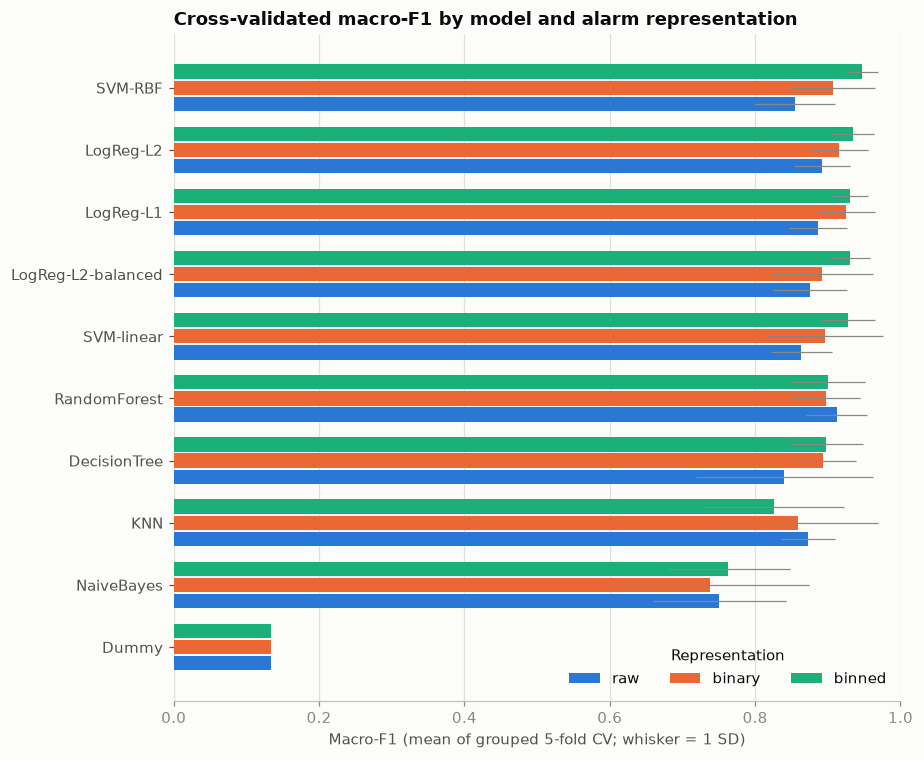

In [7]:
piv = results.pivot(index="model", columns="rep", values="cv_macro_f1")[REPS]
err = results.pivot(index="model", columns="rep", values="cv_macro_f1_std")[REPS]
order = piv.max(axis=1).sort_values().index
piv, err = piv.loc[order], err.loc[order]
fig, ax = plt.subplots(figsize=(8.5, 7))
h = 0.26; ypos = np.arange(len(order))
for k, rep in enumerate(REPS):
    ax.barh(ypos + (k - 1) * h, piv[rep], height=h - 0.03, color=SERIES[k], label=rep,
            xerr=err[rep], error_kw={"ecolor": MUTED, "elinewidth": 0.8, "capsize": 0})
ax.set_yticks(ypos, order); ax.set_xlim(0, 1.0); ax.grid(axis="y", visible=False)
ax.set_xlabel("Macro-F1 (mean of grouped 5-fold CV; whisker = 1 SD)")
ax.set_title("Cross-validated macro-F1 by model and alarm representation")
best = results.iloc[0]
ax.legend(title="Representation", loc="lower right", ncols=3)
plt.tight_layout(); plt.savefig(FIG / "model_comparison.png", dpi=160); plt.show()

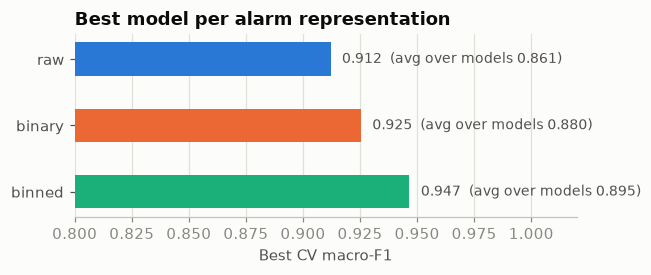

,best_cv_macro_f1,mean_over_models
rep,,
raw,0.912,0.861
binary,0.925,0.880
binned,0.947,0.895


In [8]:
rep_best = results.groupby("rep")[["cv_macro_f1"]].max().loc[REPS]
rep_mean = results[results.model != "Dummy"].groupby("rep")["cv_macro_f1"].mean().loc[REPS]
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(REPS[::-1], rep_best["cv_macro_f1"][::-1], color=[SERIES[i] for i in (2, 1, 0)], height=0.5)
for r, v in rep_best["cv_macro_f1"].items():
    ax.text(v + 0.005, REPS[::-1].index(r), f"{v:.3f}  (avg over models {rep_mean[r]:.3f})", va="center", color=INK2, fontsize=9)
ax.set_xlim(0.8, 1.02); ax.grid(axis="y", visible=False); ax.set_xlabel("Best CV macro-F1")
ax.set_title("Best model per alarm representation")
plt.tight_layout(); plt.savefig(FIG / "representation_comparison.png", dpi=160); plt.show()
pd.DataFrame({"best_cv_macro_f1": rep_best["cv_macro_f1"], "mean_over_models": rep_mean}).round(3)

## 6. Select by CV and evaluate once on the held-out test set

In [9]:
sel = results.iloc[0]
final_key = (sel.model, sel.rep)
final_model = fitted[final_key]
if isinstance(final_model.named_steps["clf"], SVC):
    # enable class probabilities for the demo (Platt scaling); SVC.predict still uses the decision
    # function, so predicted labels are unchanged. Refit on the training set only.
    final_model = sklearn.base.clone(final_model).set_params(clf__probability=True, clf__random_state=SEED).fit(X_tr, y_tr)
print("Selected:", final_key, "params", sel.best_params, f"| CV macro-F1 {sel.cv_macro_f1:.3f} ± {sel.cv_macro_f1_std:.3f}")
y_pred = final_model.predict(X_te)
names = [CLASS_NAMES[i] for i in range(4)]
final_metrics = {"accuracy": accuracy_score(y_te, y_pred), "balanced_accuracy": balanced_accuracy_score(y_te, y_pred),
                 "macro_f1": f1_score(y_te, y_pred, average="macro"), "weighted_f1": f1_score(y_te, y_pred, average="weighted")}
print(json.dumps({k: round(v, 4) for k, v in final_metrics.items()}, indent=2))
print(classification_report(y_te, y_pred, target_names=names, digits=3))

/Users/avishipoddar/Downloads/proj/.venv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Selected: ('SVM-RBF', 'binned') params {"C": 10, "gamma": "scale"} | CV macro-F1 0.947 ± 0.022
{
  "accuracy": 0.9611,
  "balanced_accuracy": 0.9503,
  "macro_f1": 0.9567,
  "weighted_f1": 0.9609
}
              precision    recall  f1-score   support

         IDU      0.953     0.981     0.967       103
         ODU      0.960     0.975     0.967       122
       Cable      0.974     0.905     0.938        42
       Power      0.969     0.940     0.955        67

    accuracy                          0.961       334
   macro avg      0.964     0.950     0.957       334
weighted avg      0.961     0.961     0.961       334



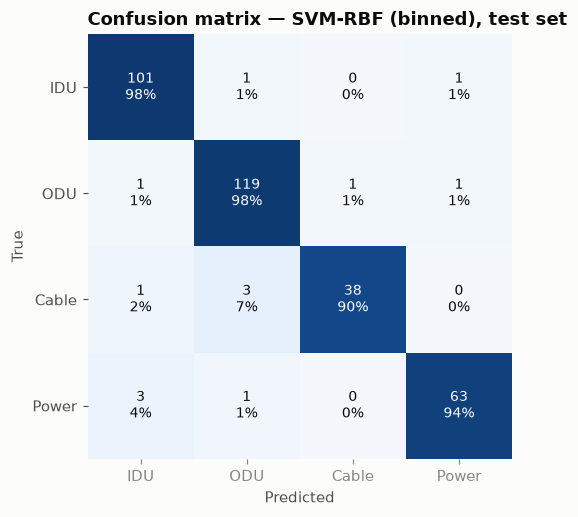

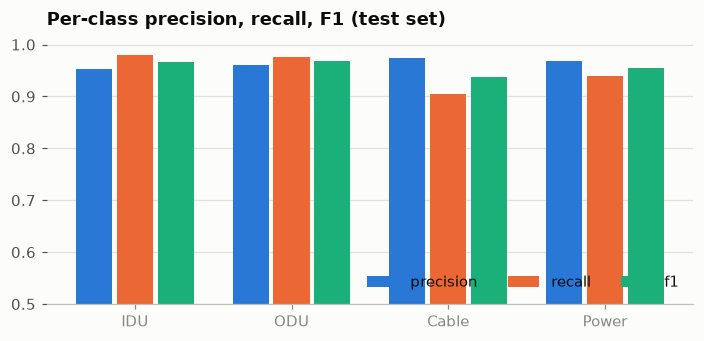

,precision,recall,f1,support
IDU,0.953,0.981,0.967,103
ODU,0.960,0.975,0.967,122
Cable,0.974,0.905,0.938,42
Power,0.969,0.940,0.955,67


In [10]:
cm = confusion_matrix(y_te, y_pred, labels=[0, 1, 2, 3])
cmn = cm / cm.sum(axis=1, keepdims=True)
seq = LinearSegmentedColormap.from_list("seq_blue", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(5.6, 4.8))
ax.imshow(cmn, cmap=seq, vmin=0, vmax=1); ax.grid(False)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.0%}", ha="center", va="center", fontsize=9,
                color="white" if cmn[i, j] > 0.55 else INK)
ax.set_xticks(range(4), names); ax.set_yticks(range(4), names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
ax.set_title(f"Confusion matrix — {final_key[0]} ({final_key[1]}), test set")
for s in ax.spines.values(): s.set_visible(False)
plt.tight_layout(); plt.savefig(FIG / "confusion_matrix.png", dpi=160); plt.show()

p, r, f, sup = precision_recall_fscore_support(y_te, y_pred, labels=[0, 1, 2, 3])
per_class = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": sup}, index=names)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
w = 0.26; xs = np.arange(4)
for k, m in enumerate(["precision", "recall", "f1"]):
    ax.bar(xs + (k - 1) * w, per_class[m], width=w - 0.03, color=SERIES[k], label=m)
ax.set_xticks(xs, names); ax.set_ylim(0.5, 1.02); ax.grid(axis="x", visible=False)
ax.set_title("Per-class precision, recall, F1 (test set)"); ax.legend(ncols=3, loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "per_class_metrics.png", dpi=160); plt.show()
per_class.round(3)

In [11]:
# save final pipeline + test predictions
joblib.dump(final_model, MOD / "final_model.joblib")
pred = pd.DataFrame({"row_index": X_te.index, "vector_group": g_te, "y_true": y_te.values, "y_pred": y_pred,
                     "true_name": y_te.map(CLASS_NAMES).values, "pred_name": pd.Series(y_pred).map(CLASS_NAMES).values})
if hasattr(final_model, "predict_proba"):
    proba = final_model.predict_proba(X_te)
    for i in range(4): pred[f"p_{CLASS_NAMES[i]}"] = proba[:, i].round(4)
pred.to_csv(REP / "test_predictions.csv", index=False)
print("misclassified test rows:", int((pred.y_true != pred.y_pred).sum()), "of", len(pred))
pred[pred.y_true != pred.y_pred].head(20)

misclassified test rows: 13 of 334


,row_index,vector_group,y_true,y_pred,true_name,pred_name,p_IDU,p_ODU,p_Cable,p_Power
11,44,39,0,3,IDU,Power,0.3741,0.0005,0.0003,0.6251
28,177,145,3,0,Power,IDU,0.5100,0.2569,0.0619,0.1712
41,245,196,1,2,ODU,Cable,0.0719,0.2819,0.6115,0.0347
54,293,231,1,3,ODU,Power,0.0316,0.4656,0.0276,0.4751
84,442,336,1,0,ODU,IDU,0.8228,0.0951,0.0136,0.0685
91,461,346,3,1,Power,ODU,0.2074,0.4706,0.1336,0.1883
107,565,412,3,0,Power,IDU,0.5416,0.1222,0.0153,0.3209
159,831,593,2,1,Cable,ODU,0.1462,0.4804,0.3604,0.0130
167,857,610,2,1,Cable,ODU,0.1292,0.2763,0.4069,0.1875
173,876,622,3,0,Power,IDU,0.9655,0.0039,0.0021,0.0285


## 7. Leakage check — plain stratified CV vs grouped CV (same tuned settings)

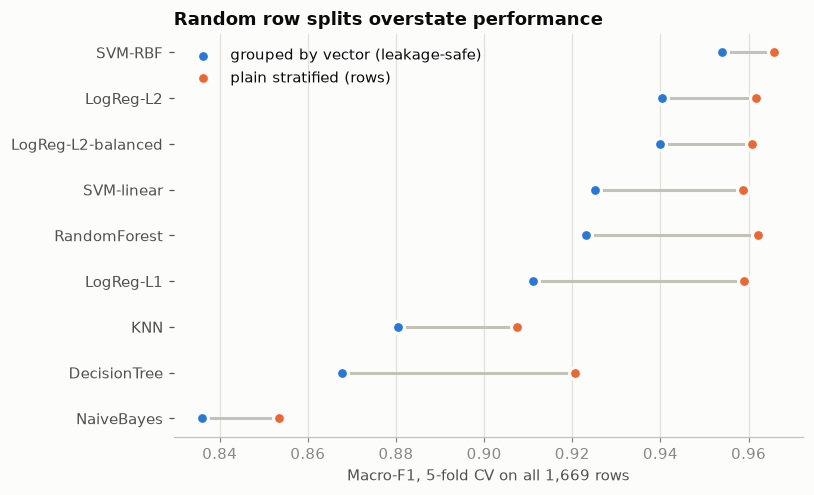

,model,rep,plain_stratified_cv,grouped_cv,gap
8,NaiveBayes,binned,0.853,0.836,0.017
5,DecisionTree,binned,0.921,0.868,0.053
7,KNN,raw,0.908,0.880,0.027
2,LogReg-L1,binned,0.959,0.911,0.048
6,RandomForest,raw,0.962,0.923,0.039
3,SVM-linear,binned,0.959,0.925,0.034
1,LogReg-L2-balanced,binned,0.961,0.940,0.021
0,LogReg-L2,binned,0.962,0.940,0.021
4,SVM-RBF,binned,0.966,0.954,0.012


In [12]:
plain = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
grouped = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
leak_rows = []
for name in [m for m in MODELS if m != "Dummy"]:
    rep = results[results.model == name].iloc[0].rep          # each model's own best representation
    est = fitted[(name, rep)]
    a = cross_validate(est, X, y, cv=plain, scoring="f1_macro", n_jobs=-1)["test_score"]
    b = cross_validate(est, X, y, cv=grouped, groups=groups, scoring="f1_macro", n_jobs=-1)["test_score"]
    leak_rows.append({"model": name, "rep": rep, "plain_stratified_cv": a.mean(), "grouped_cv": b.mean(), "gap": a.mean() - b.mean()})
leak = pd.DataFrame(leak_rows).sort_values("grouped_cv")
leak.to_csv(REP / "leakage_check.csv", index=False)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
yy = np.arange(len(leak))
ax.hlines(yy, leak.grouped_cv, leak.plain_stratified_cv, color=AXIS, lw=2)
ax.scatter(leak.grouped_cv, yy, s=60, color=SERIES[0], label="grouped by vector (leakage-safe)", zorder=3, edgecolor=SURF, linewidth=2)
ax.scatter(leak.plain_stratified_cv, yy, s=60, color=SERIES[1], label="plain stratified (rows)", zorder=3, edgecolor=SURF, linewidth=2)
ax.set_yticks(yy, leak.model); ax.grid(axis="y", visible=False)
ax.set_xlabel("Macro-F1, 5-fold CV on all 1,669 rows")
ax.set_title("Random row splits overstate performance")
ax.legend(loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "split_leakage.png", dpi=160); plt.show()
leak.round(3)

## 8. Class imbalance — class weighting and SMOTE (Cable is the minority class)

In [13]:
imb_rows = []
cable_recall = lambda yt, yp: precision_recall_fscore_support(yt, yp, labels=[2], zero_division=0)[1][0]
from sklearn.metrics import make_scorer
scoring = {"macro_f1": "f1_macro", "cable_recall": make_scorer(cable_recall)}
for name in ["LogReg-L2", "RandomForest"]:
    rep = results[results.model == name].iloc[0].rep
    base = fitted[(name, rep)]
    variants = {"none": base}
    if name == "LogReg-L2":
        variants["class_weight=balanced"] = fitted[("LogReg-L2-balanced", rep)]
    else:
        variants["class_weight=balanced"] = sklearn.base.clone(base).set_params(clf__class_weight="balanced")
    variants["SMOTE (train folds only)"] = ImbPipeline(list(sklearn.base.clone(base).steps[:-1]) +
                                           [("smote", SMOTE(random_state=SEED)), ("clf", sklearn.base.clone(base.named_steps["clf"]))])
    for v, est in variants.items():
        s = cross_validate(est, X_tr, y_tr, cv=inner, groups=g_tr, scoring=scoring, n_jobs=-1)
        imb_rows.append({"model": name, "rep": rep, "imbalance_handling": v,
                         "cv_macro_f1": s["test_macro_f1"].mean(), "cv_cable_recall": s["test_cable_recall"].mean()})
imb = pd.DataFrame(imb_rows); imb.to_csv(REP / "imbalance_experiments.csv", index=False); imb.round(3)

,model,rep,imbalance_handling,cv_macro_f1,cv_cable_recall
0,LogReg-L2,binned,none,0.935,0.915
1,LogReg-L2,binned,class_weight=balanced,0.930,0.921
2,LogReg-L2,binned,SMOTE (train folds only),0.934,0.921
3,RandomForest,raw,none,0.912,0.897
4,RandomForest,raw,class_weight=balanced,0.913,0.927
5,RandomForest,raw,SMOTE (train folds only),0.914,0.909


## 9. Which alarms are most informative?
Two independent views: (a) the sparse **L1 logistic regression** on binary alarms — which alarms survive and in which direction they push each class;
(b) **permutation importance** of the Random Forest on the held-out test set. Alarm IDs are anonymised, so these are predictive signals, not physical causes.

L1 (binary, C=1): 57 of 119 non-constant alarms have a non-zero weight


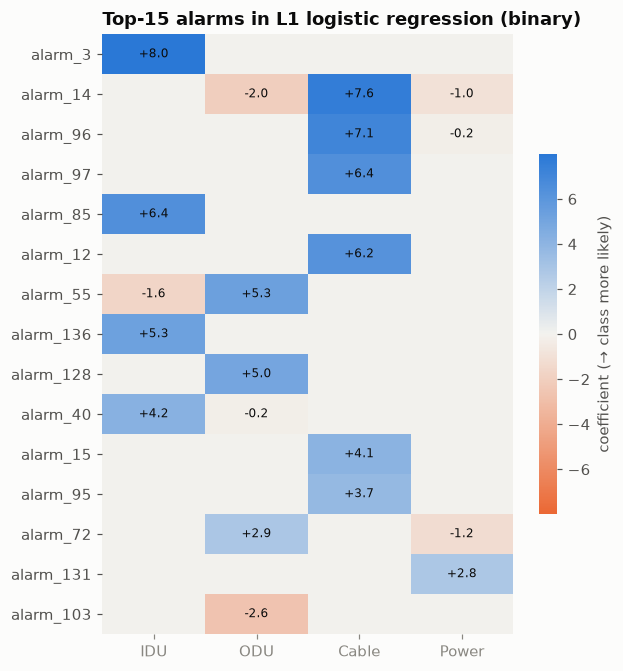

In [14]:
l1 = fitted[("LogReg-L1", "binary")]
kept = X.columns[l1.named_steps["drop_const"].get_support()]
coef = pd.DataFrame(l1.named_steps["clf"].coef_.T, index=kept, columns=names)
nz = (coef.abs() > 1e-8).any(axis=1)
print(f"L1 (binary, C={l1.named_steps['clf'].C}): {nz.sum()} of {len(kept)} non-constant alarms have a non-zero weight")
top = coef.loc[coef.abs().max(axis=1).sort_values(ascending=False).index[:15]]
div = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f3f2ee", "#2a78d6"])
lim = np.abs(top.values).max()
fig, ax = plt.subplots(figsize=(5.8, 6.2))
im = ax.imshow(top.values, cmap=div, vmin=-lim, vmax=lim, aspect="auto"); ax.grid(False)
for i in range(top.shape[0]):
    for j in range(4):
        v = top.values[i, j]
        if abs(v) > 1e-8: ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8, color=INK)
ax.set_xticks(range(4), names); ax.set_yticks(range(len(top)), top.index)
for s in ax.spines.values(): s.set_visible(False)
cb = plt.colorbar(im, ax=ax, shrink=0.6); cb.outline.set_visible(False); cb.set_label("coefficient (→ class more likely)")
ax.set_title("Top-15 alarms in L1 logistic regression (binary)")
plt.tight_layout(); plt.savefig(FIG / "l1_coefficients.png", dpi=160); plt.show()
coef.to_csv(REP / "l1_logreg_coefficients.csv")

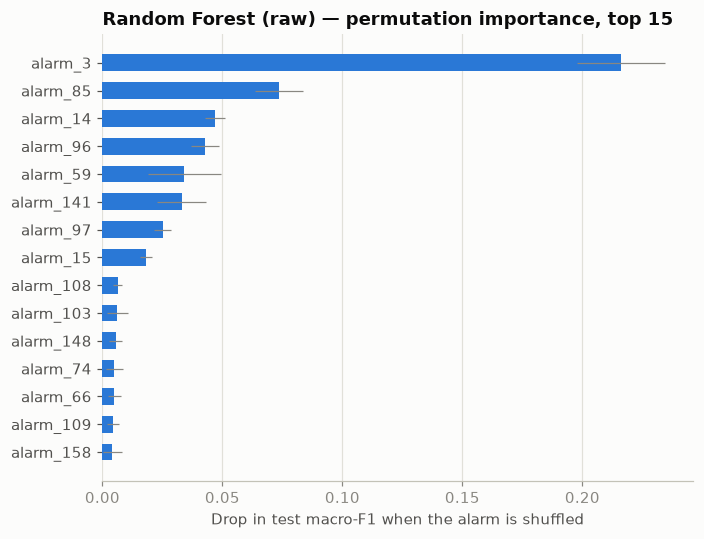

Alarms in BOTH top-15 lists: ['alarm_3', 'alarm_14', 'alarm_15', 'alarm_85', 'alarm_96', 'alarm_97', 'alarm_103']


In [15]:
rf_rep = results[results.model == "RandomForest"].iloc[0].rep
rf = fitted[("RandomForest", rf_rep)]
pi = permutation_importance(rf, X_te, y_te, scoring="f1_macro", n_repeats=20, random_state=SEED, n_jobs=-1)
imp = pd.DataFrame({"mean_drop_macro_f1": pi.importances_mean, "std": pi.importances_std}, index=X.columns)
imp = imp.sort_values("mean_drop_macro_f1", ascending=False); imp.to_csv(REP / "rf_permutation_importance.csv")
t15 = imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.barh(t15.index, t15.mean_drop_macro_f1, xerr=t15["std"], color=SERIES[0], height=0.6,
        error_kw={"ecolor": MUTED, "elinewidth": 0.8, "capsize": 0})
ax.grid(axis="y", visible=False); ax.set_xlabel("Drop in test macro-F1 when the alarm is shuffled")
ax.set_title(f"Random Forest ({rf_rep}) — permutation importance, top 15")
plt.tight_layout(); plt.savefig(FIG / "rf_permutation_importance.png", dpi=160); plt.show()
overlap = set(imp.head(15).index) & set(coef.abs().max(axis=1).sort_values(ascending=False).index[:15])
print("Alarms in BOTH top-15 lists:", sorted(overlap, key=lambda s: int(s.split('_')[1])))

## 10. Demonstration — load the saved pipeline and diagnose unseen windows

In [16]:
model = joblib.load(MOD / "final_model.joblib")       # one object: preprocessing + classifier
demo = X_te.sample(6, random_state=7)
out = pd.DataFrame({"true": y_te.loc[demo.index].map(CLASS_NAMES), "predicted": pd.Series(model.predict(demo), index=demo.index).map(CLASS_NAMES)})
if hasattr(model, "predict_proba"):
    out = out.join(pd.DataFrame(model.predict_proba(demo), index=demo.index, columns=[f"P({n})" for n in names]).round(3))
out["active alarms"] = (demo > 0).sum(axis=1)
out

,true,predicted,P(IDU),P(ODU),P(Cable),P(Power),active alarms
1511,ODU,ODU,0.006,0.990,0.002,0.002,12
1187,ODU,ODU,0.006,0.990,0.002,0.002,12
327,IDU,IDU,0.986,0.001,0.001,0.013,8
358,ODU,ODU,0.006,0.990,0.002,0.002,12
1642,Power,Power,0.017,0.025,0.005,0.953,7
863,ODU,ODU,0.006,0.990,0.002,0.002,12


## 11. Summary written to `reports/model_results.md`

In [17]:
L = []
L.append("# Model results (auto-generated by notebooks/02_model_experiments.ipynb)\n")
L.append(f"Seed {SEED}; sklearn {sklearn.__version__}; xgboost {XGB_VERSION}. Train {len(train_idx)} rows / test {len(test_idx)} rows, "
         f"split with StratifiedGroupKFold grouped by identical 164-alarm vector (no vector in both).\n")
L.append("## Data checks\n")
L += [f"- {k.replace('_', ' ')}: {v}" for k, v in dup_summary.items()]
L.append("\n## Selected model (by grouped-CV macro-F1 on training data)\n")
L.append(f"**{sel.model}** on **{sel.rep}** features, params `{sel.best_params}`; CV macro-F1 {sel.cv_macro_f1:.3f} ± {sel.cv_macro_f1_std:.3f}.\n")
L.append("Held-out test: " + ", ".join(f"{k} {v:.3f}" for k, v in final_metrics.items()) + "\n")
L.append(per_class.round(3).to_markdown() + "\n")
L.append("## All models (sorted by CV macro-F1)\n")
L.append(results[["model", "rep", "cv_macro_f1", "cv_macro_f1_std", "cv_balanced_acc", "test_macro_f1", "test_cable_recall", "best_params"]].round(3).to_markdown(index=False) + "\n")
L.append("Test columns are shown for transparency only; selection used CV alone.\n")
L.append("## Leakage check (5-fold CV on all rows)\n" + leak.round(3).to_markdown(index=False) + "\n")
L.append("## Imbalance handling (grouped CV, training set)\n" + imb.round(3).to_markdown(index=False) + "\n")
L.append(f"## Informative alarms\n- L1 LogReg (binary) keeps {nz.sum()} of {len(kept)} non-constant alarms.\n"
         f"- RF permutation top-10: {', '.join(imp.head(10).index)}\n- In both top-15 lists: {', '.join(sorted(overlap, key=lambda s: int(s.split('_')[1])))}\n")
(REP / "model_results.md").write_text("\n".join(L))
print("\n".join(L)[:3000])

# Model results (auto-generated by notebooks/02_model_experiments.ipynb)

Seed 42; sklearn 1.9.1; xgboost not installed. Train 1335 rows / test 334 rows, split with StratifiedGroupKFold grouped by identical 164-alarm vector (no vector in both).

## Data checks

- rows: 1669
- unique input vectors: 1135
- rows whose vector repeats: 584
- largest group size: 69
- vectors with conflicting labels: 0

## Selected model (by grouped-CV macro-F1 on training data)

**SVM-RBF** on **binned** features, params `{"C": 10, "gamma": "scale"}`; CV macro-F1 0.947 ± 0.022.

Held-out test: accuracy 0.961, balanced_accuracy 0.950, macro_f1 0.957, weighted_f1 0.961

|       |   precision |   recall |    f1 |   support |
|:------|------------:|---------:|------:|----------:|
| IDU   |       0.953 |    0.981 | 0.967 |       103 |
| ODU   |       0.96  |    0.975 | 0.967 |       122 |
| Cable |       0.974 |    0.905 | 0.938 |        42 |
| Power |       0.969 |    0.94  | 0.955 |        67 |

## All models (